# Robertuito: evaluación histórica de tiendas v3

Esta libreta consulta el `evaluation.json` del checkpoint de tiendas v3, copiado sin cambios y con hash. No vuelve a entrenar ni ejecuta inferencia. **Robertuito original ya está entrenado para sentimiento**; v3 añade el ajuste de dominio del equipo.

La prueba histórica contiene 14.438 reseñas de tiendas con referencia derivada de estrellas. No es la muestra nueva de 1.000 reseñas. Social v2 no forma parte de la alternativa actual y no se mezcla en estas figuras. Se consultan métricas publicadas; los IDs y predicciones individuales de la prueba no están disponibles aquí.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/voc").is_dir())
NB_ROOT = REPO / "reports/difusion"
if str(NB_ROOT) not in sys.path: sys.path.insert(0, str(NB_ROOT))
from apoyo_validacion import digest, export_bundle, show_texts
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
source = NB_ROOT/"sources/robertuito-tiendas-v3-evaluation.json"
provenance = json.loads((NB_ROOT/"sources/provenance.json").read_text())
assert digest(source) == provenance["sha256"]
evaluation = json.loads(source.read_text())
labels = evaluation["label_order"]
print("Checkpoint:",provenance["model"],provenance["revision"])
print("Hash del conjunto histórico:",evaluation["data_sha256"])
print("Referencia: estrellas de tiendas; no evaluación humana independiente del texto.")


Checkpoint: Banamex-voc-sentiment/voc-robertuito-sentiment-stores-es ff48c25f016499fc40d910f2a2a50072c706cdee
Hash del conjunto histórico: e8bc49e6767d6e5335c4d58699ee0231999205138f7f277f93f62a929461b926
Referencia: estrellas de tiendas; no evaluación humana independiente del texto.


## Desempeño agregado y por clase

Accuracy es la fracción de aciertos. Macro-F1 promedia F1 de negativa, neutral y positiva con el mismo peso; weighted-F1 pondera por sus soportes. Mostramos ambos modelos sobre la prueba descrita en el mismo archivo. La proporción de positivos ayuda a entender por qué accuracy y macro-F1 cuentan historias diferentes.

El aumento de macro-F1 no significa que todas las clases alcancen desempeño suficiente. Observa especialmente recall y F1 neutral, y distingue una mejora frente al original de un resultado adecuado para el uso deseado.


,model,accuracy,macro_f1,weighted_f1,test_rows
0,Original,0.720252,0.570764,0.767289,14438
1,Tiendas v3,0.890982,0.674440,0.881467,14438


,model,label,precision,recall,f1-score,support
0,Original,negative,0.6752,0.9089,0.7748,3238.0
1,Original,neutral,0.0756,0.2233,0.1129,936.0
2,Original,positive,0.9910,0.7061,0.8246,10264.0
3,Tiendas v3,negative,0.7743,0.8944,0.8300,3238.0
4,Tiendas v3,neutral,0.3562,0.1774,0.2368,936.0
5,Tiendas v3,positive,0.9580,0.9550,0.9565,10264.0


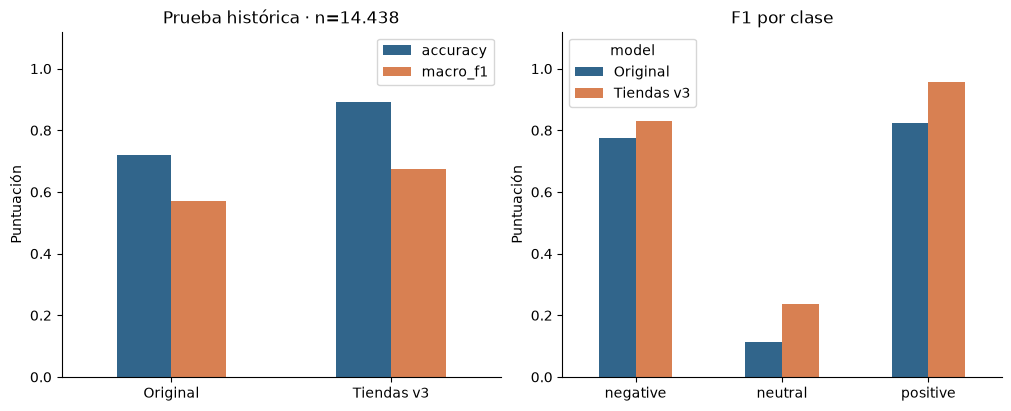

In [3]:
overall_rows=[];class_rows=[]
for name,key in [("Original","baseline_test"),("Tiendas v3","test")]:
    report=evaluation[key]
    overall_rows.append({"model":name,"accuracy":report["accuracy"],"macro_f1":report["macro avg"]["f1-score"],"weighted_f1":report["weighted avg"]["f1-score"],"test_rows":int(report["macro avg"]["support"])})
    for label in labels:class_rows.append({"model":name,"label":label,**report[label]})
overall=pd.DataFrame(overall_rows);classes=pd.DataFrame(class_rows)
assert overall.test_rows.eq(14438).all()
for name,group in classes.groupby("model"):
    assert group.support.sum()==14438
    assert np.isclose(group["f1-score"].mean(),overall.set_index("model").loc[name,"macro_f1"])
display(overall.round(6));display(classes.round(4))
fig_metrics, axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
overall.set_index("model")[["accuracy","macro_f1"]].plot.bar(ax=axes[0],rot=0,color=["#31658B","#D88052"])
classes.pivot(index="label",columns="model",values="f1-score").reindex(labels).plot.bar(ax=axes[1],rot=0,color=["#31658B","#D88052"])
for ax in axes:ax.set(ylim=(0,1.12),ylabel="Puntuación",xlabel="")
axes[0].set_title("Prueba histórica · n=14.438");axes[1].set_title("F1 por clase")
plt.show()


## Matriz de confusión y soporte

Aquí sí hay etiquetas de referencia: filas = estrellas convertidas a sentimiento, columnas = predicción de v3. La matriz original no está incluida en el archivo, por lo que no se inventa ni se reconstruye a partir de métricas redondeadas. Verificamos que la matriz de v3 coincide con sus soportes, accuracy, precisión, recall y F1 publicados.


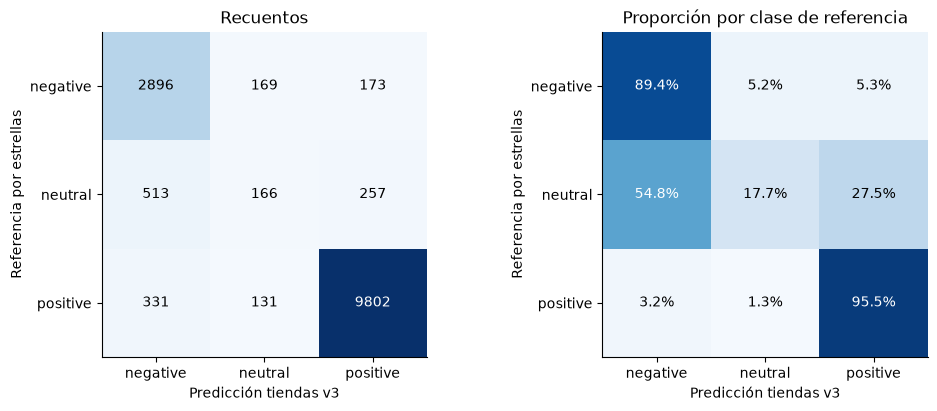

In [4]:
cm=np.asarray(evaluation["confusion_matrix"])
assert cm.sum()==14438
support=np.array([evaluation["test"][label]["support"] for label in labels])
assert np.array_equal(cm.sum(axis=1),support)
p=np.diag(cm)/cm.sum(axis=0);r=np.diag(cm)/cm.sum(axis=1);f=2*p*r/(p+r)
assert np.isclose(np.trace(cm)/cm.sum(),evaluation["test"]["accuracy"])
for i,label in enumerate(labels):
    for metric,value in [("precision",p[i]),("recall",r[i]),("f1-score",f[i])]:assert np.isclose(value,evaluation["test"][label][metric])
fig_confusion,axes=plt.subplots(1,2,figsize=(10,4),layout="constrained")
for ax,values,title,percent in [(axes[0],cm,"Recuentos",False),(axes[1],cm/cm.sum(axis=1,keepdims=True),"Proporción por clase de referencia",True)]:
    ax.imshow(values,cmap="Blues",vmin=0,vmax=1 if percent else cm.max())
    for i in range(3):
        for j in range(3):ax.text(j,i,f"{values[i,j]:.1%}" if percent else str(values[i,j]),ha="center",va="center",color="white" if values[i,j]> (0.5 if percent else cm.max()/2) else "black")
    ax.set(xticks=range(3),yticks=range(3),xticklabels=labels,yticklabels=labels,xlabel="Predicción tiendas v3",ylabel="Referencia por estrellas",title=title)
plt.show()


## Qué se ajustó y cómo se seleccionó el checkpoint

Los valores siguientes son registros del entrenamiento anterior: último bloque del encoder y clasificador, tres épocas, selección por macro-F1 de validación. La prueba se reporta aparte. No se elige una época usando el test ni se atribuye a esta libreta una reproducción del entrenamiento.

Las estrellas son supervisión aproximada, la clase neutral tiene soporte menor y no conocemos los IDs para descartar solapamiento con la nueva muestra. Por ello estas métricas no se trasladan automáticamente a X/YouTube ni explican cuáles de los 314 cambios de predicción actuales son aciertos.


,training_mode,encoder_blocks_trained,total_parameters,trainable_parameters,trainable_percent,epochs,batch_size,learning_rate,max_length,best_epoch
0,last_n,1,108791043,7680771,7.060113,3,8,0.00002,128,3


,epoch,loss,validation_macro_f1
0,1,0.335053,0.675600
1,2,0.310442,0.658435
2,3,0.300575,0.681915


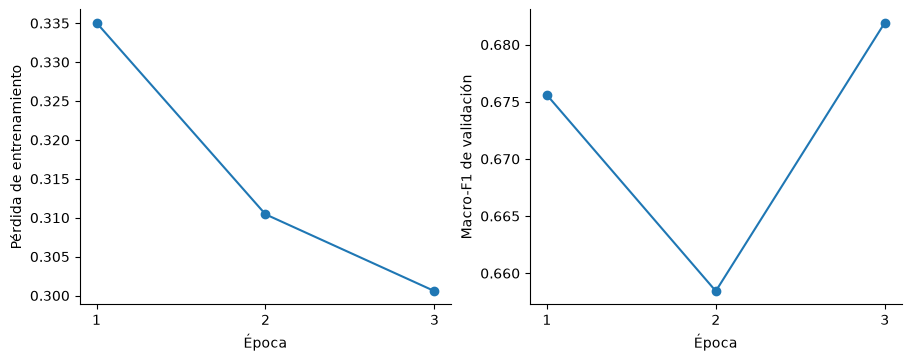

In [5]:
history=pd.DataFrame(evaluation["history"])
training=pd.DataFrame([{k:evaluation[k] for k in ["training_mode","encoder_blocks_trained","total_parameters","trainable_parameters","trainable_percent","epochs","batch_size","learning_rate","max_length","best_epoch"]}])
display(training);display(history)
assert evaluation["best_epoch"]==int(history.loc[history.validation_macro_f1.idxmax(),"epoch"])
fig_history,axes=plt.subplots(1,2,figsize=(9,3.5),layout="constrained")
axes[0].plot(history.epoch,history.loss,marker="o");axes[0].set(xlabel="Época",ylabel="Pérdida de entrenamiento")
axes[1].plot(history.epoch,history.validation_macro_f1,marker="o");axes[1].set(xlabel="Época",ylabel="Macro-F1 de validación")
for ax in axes:ax.set_xticks(history.epoch)
plt.show()


## Exportación

Exportamos los resultados de la libreta para elaborar el reporte.


In [6]:
exported=export_bundle(NB_ROOT/"evaluacion-historica-robertuito.ipynb",
 {"robertuito-metricas":fig_metrics,"robertuito-confusion-v3":fig_confusion,"robertuito-entrenamiento-historico":fig_history},
 {"metricas-agregadas":overall,"metricas-por-clase":classes,"historial-entrenamiento":history,"configuracion-entrenamiento":training,
  "matriz-confusion-v3":pd.DataFrame(cm,index=labels,columns=labels).rename_axis("reference").reset_index()},
 {"procedencia":provenance},
 {"evaluation":{"path":str(source.relative_to(REPO)),"sha256":digest(source)}},
 "Historical stores-v3 evaluation; rating-based labels; aggregate reproduction only, not retraining or independent testing")


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/evaluacion-historica-robertuito/20261105T191415696114Z
